In [2]:
import os
import cv2
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\ASUS\Desktop\ipd


In [3]:
train_df = pd.read_csv("train/_classes.csv")
valid_df = pd.read_csv("valid/_classes.csv")
test_df = pd.read_csv("test/_classes.csv")

print("Train Shape :", train_df.shape)
print("Validation Shape :", valid_df.shape)
print("Test Shape :", test_df.shape)

Train Shape : (1418, 17)
Validation Shape : (174, 17)
Test Shape : (176, 17)


In [4]:
train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"

In [5]:
df = pd.concat(
    [train_df, valid_df, test_df],
    ignore_index=True
)

print("Total Images :", len(df))

Total Images : 1768


In [6]:
print("DATASET SHAPE")
print(df.shape)

DATASET SHAPE
(1768, 18)


In [7]:
print(df.columns.tolist())

['filename', ' anold-chiari-malformation', ' arachnoid-cyst', ' cerebellah-hypoplasia', ' colphocephaly', ' encephalocele', ' holoprosencephaly', ' hydracenphaly', ' intracranial-hemorrdge', ' intracranial-tumor', ' m-magna', ' mild-ventriculomegaly', ' moderate-ventriculomegaly', ' normal', ' polencephaly', ' severe-ventriculomegaly', ' vein-of-galen', 'split']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1768 entries, 0 to 1767
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   filename                    1768 non-null   object
 1    anold-chiari-malformation  1768 non-null   int64 
 2    arachnoid-cyst             1768 non-null   int64 
 3    cerebellah-hypoplasia      1768 non-null   int64 
 4    colphocephaly              1768 non-null   int64 
 5    encephalocele              1768 non-null   int64 
 6    holoprosencephaly          1768 non-null   int64 
 7    hydracenphaly              1768 non-null   int64 
 8    intracranial-hemorrdge     1768 non-null   int64 
 9    intracranial-tumor         1768 non-null   int64 
 10   m-magna                    1768 non-null   int64 
 11   mild-ventriculomegaly      1768 non-null   int64 
 12   moderate-ventriculomegaly  1768 non-null   int64 
 13   normal                     1768 non-null   int6

In [9]:
df.head()

,filename,anold-chiari-malformation,arachnoid-cyst,cerebellah-hypoplasia,colphocephaly,encephalocele,holoprosencephaly,hydracenphaly,intracranial-hemorrdge,intracranial-tumor,m-magna,mild-ventriculomegaly,moderate-ventriculomegaly,normal,polencephaly,severe-ventriculomegaly,vein-of-galen,split
0,Copy-of-arachnoid-cyst-37b_aug_0_png_jpg.rf.3e...,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,train
1,Patient00709_Plane3_1_of_3_aug_1_png_jpg.rf.3d...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,train
2,Copy-of-mild-ventriculomegaly-24a_aug_4_png_jp...,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,train
3,Copy-of-mild-ventriculomegaly-23c_aug_3_png_jp...,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,train
4,Patient00709_Plane3_2_of_3_aug_4_png_jpg.rf.3e...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,train


,Column,Missing Values
0,filename,0
1,anold-chiari-malformation,0
2,arachnoid-cyst,0
3,cerebellah-hypoplasia,0
4,colphocephaly,0
5,encephalocele,0
6,holoprosencephaly,0
7,hydracenphaly,0
8,intracranial-hemorrdge,0
9,intracranial-tumor,0


filename                      0
 anold-chiari-malformation    0
 arachnoid-cyst               0
 cerebellah-hypoplasia        0
 colphocephaly                0
 encephalocele                0
 holoprosencephaly            0
 hydracenphaly                0
 intracranial-hemorrdge       0
 intracranial-tumor           0
 m-magna                      0
 mild-ventriculomegaly        0
 moderate-ventriculomegaly    0
 normal                       0
 polencephaly                 0
 severe-ventriculomegaly      0
 vein-of-galen                0
split                         0
dtype: int64


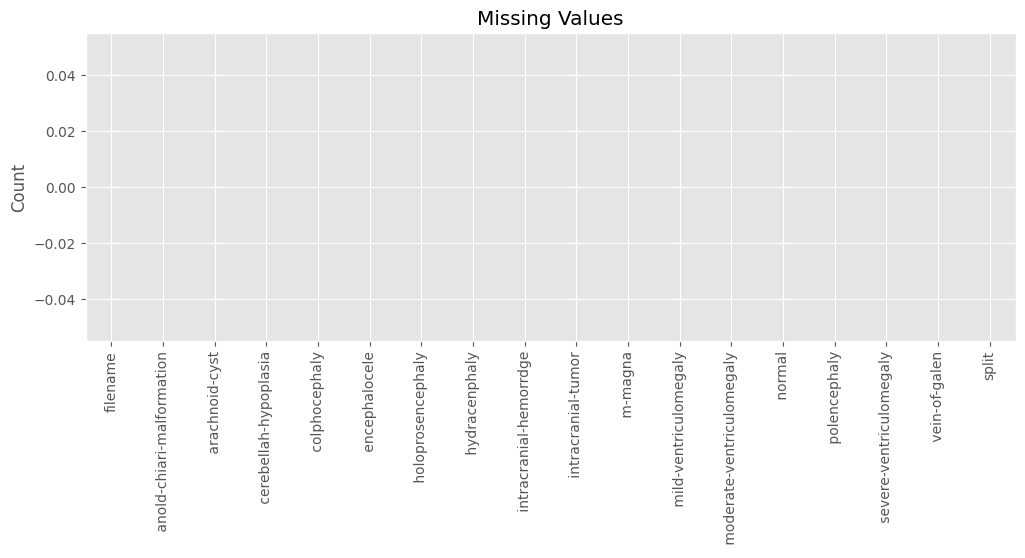

In [10]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values
})

display(missing_df)
print(missing)
plt.figure(figsize=(12,4))
missing.plot(kind="bar")
plt.title("Missing Values")
plt.ylabel("Count")
plt.show()

In [11]:
duplicates = df["filename"].duplicated().sum()
print("Duplicate Images :", duplicates)

Duplicate Images : 0


In [12]:
label_columns = df.columns[1:-1]
print("Classes")
print(label_columns.tolist())
print()
print("Total Classes :", len(label_columns))

Classes
[' anold-chiari-malformation', ' arachnoid-cyst', ' cerebellah-hypoplasia', ' colphocephaly', ' encephalocele', ' holoprosencephaly', ' hydracenphaly', ' intracranial-hemorrdge', ' intracranial-tumor', ' m-magna', ' mild-ventriculomegaly', ' moderate-ventriculomegaly', ' normal', ' polencephaly', ' severe-ventriculomegaly', ' vein-of-galen']

Total Classes : 16


In [13]:
df["label"] = df[label_columns].idxmax(axis=1)
df[["filename","label","split"]].head()

,filename,label,split
0,Copy-of-arachnoid-cyst-37b_aug_0_png_jpg.rf.3e...,arachnoid-cyst,train
1,Patient00709_Plane3_1_of_3_aug_1_png_jpg.rf.3d...,normal,train
2,Copy-of-mild-ventriculomegaly-24a_aug_4_png_jp...,mild-ventriculomegaly,train
3,Copy-of-mild-ventriculomegaly-23c_aug_3_png_jp...,mild-ventriculomegaly,train
4,Patient00709_Plane3_2_of_3_aug_4_png_jpg.rf.3e...,normal,train


In [14]:
class_counts = df["label"].value_counts()
print(class_counts)

label
moderate-ventriculomegaly    314
normal                       282
mild-ventriculomegaly        246
encephalocele                146
arachnoid-cyst               139
cerebellah-hypoplasia        130
severe-ventriculomegaly      126
polencephaly                  98
colphocephaly                 90
intracranial-hemorrdge        58
anold-chiari-malformation     50
m-magna                       38
hydracenphaly                 20
intracranial-tumor            14
holoprosencephaly             12
vein-of-galen                  5
Name: count, dtype: int64


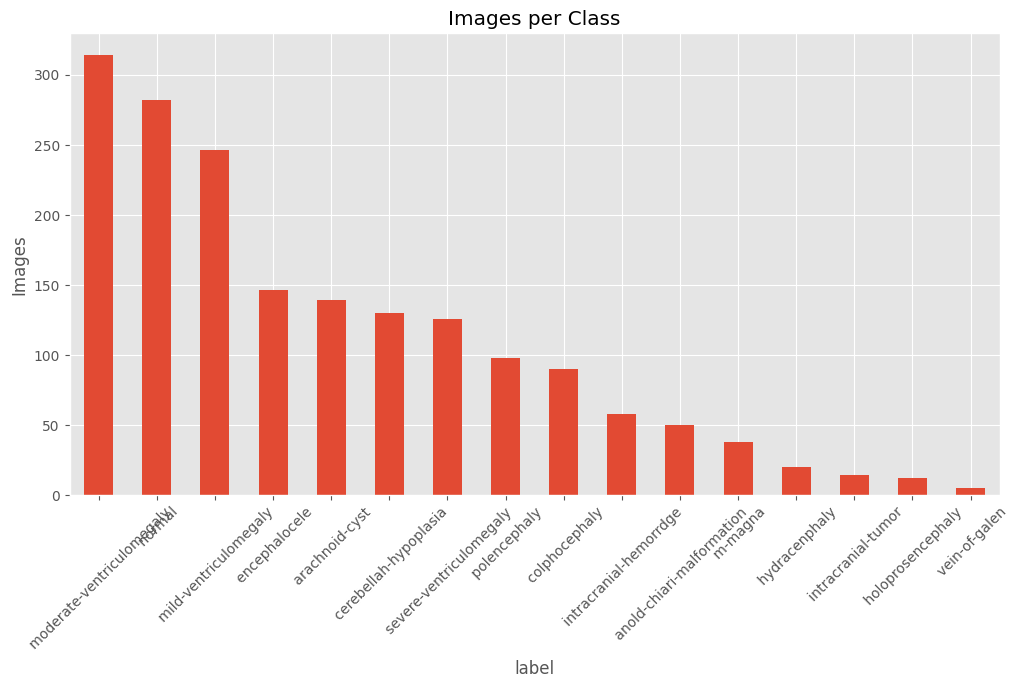

In [15]:
plt.figure(figsize=(12,6))
class_counts.plot(kind="bar")
plt.title("Images per Class")
plt.ylabel("Images")
plt.xticks(rotation=45)
plt.show()

In [16]:
percentage = class_counts/class_counts.sum()*100
percentage

label
moderate-ventriculomegaly    17.760181
normal                       15.950226
mild-ventriculomegaly        13.914027
encephalocele                 8.257919
arachnoid-cyst                7.861991
cerebellah-hypoplasia         7.352941
severe-ventriculomegaly       7.126697
polencephaly                  5.542986
colphocephaly                 5.090498
intracranial-hemorrdge        3.280543
anold-chiari-malformation     2.828054
m-magna                       2.149321
hydracenphaly                 1.131222
intracranial-tumor            0.791855
holoprosencephaly             0.678733
vein-of-galen                 0.282805
Name: count, dtype: float64

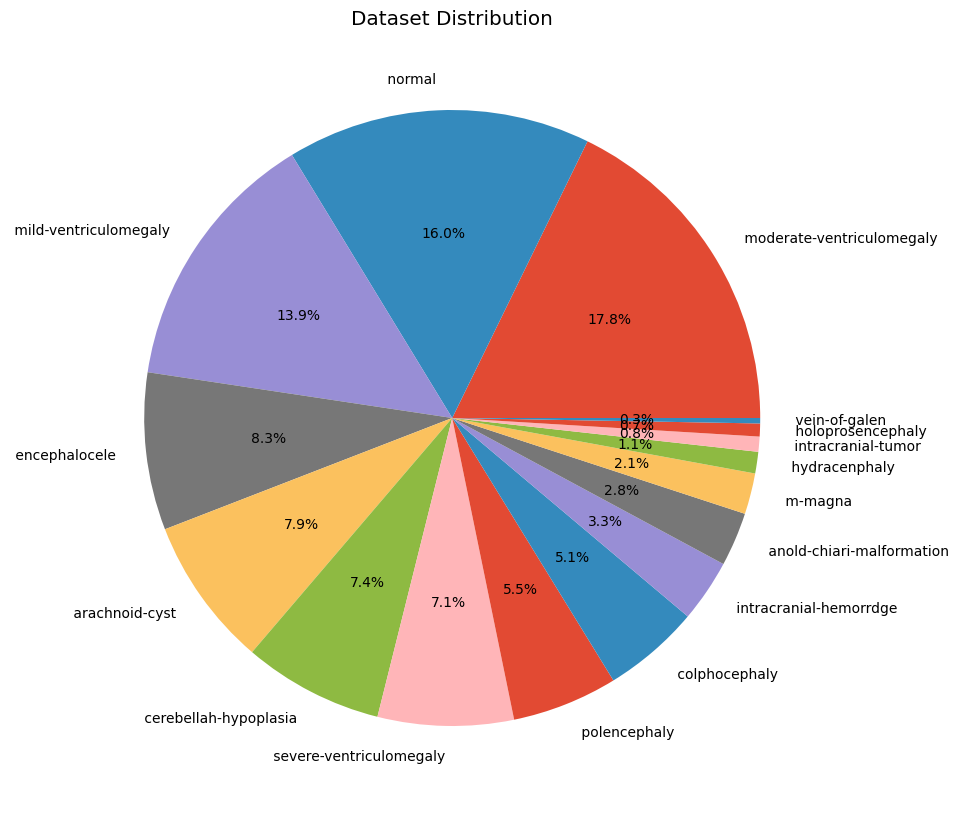

In [17]:
plt.figure(figsize=(10,10))

plt.pie(
    percentage,
    labels=percentage.index,
    autopct="%1.1f%%"
)
plt.title("Dataset Distribution")
plt.show()

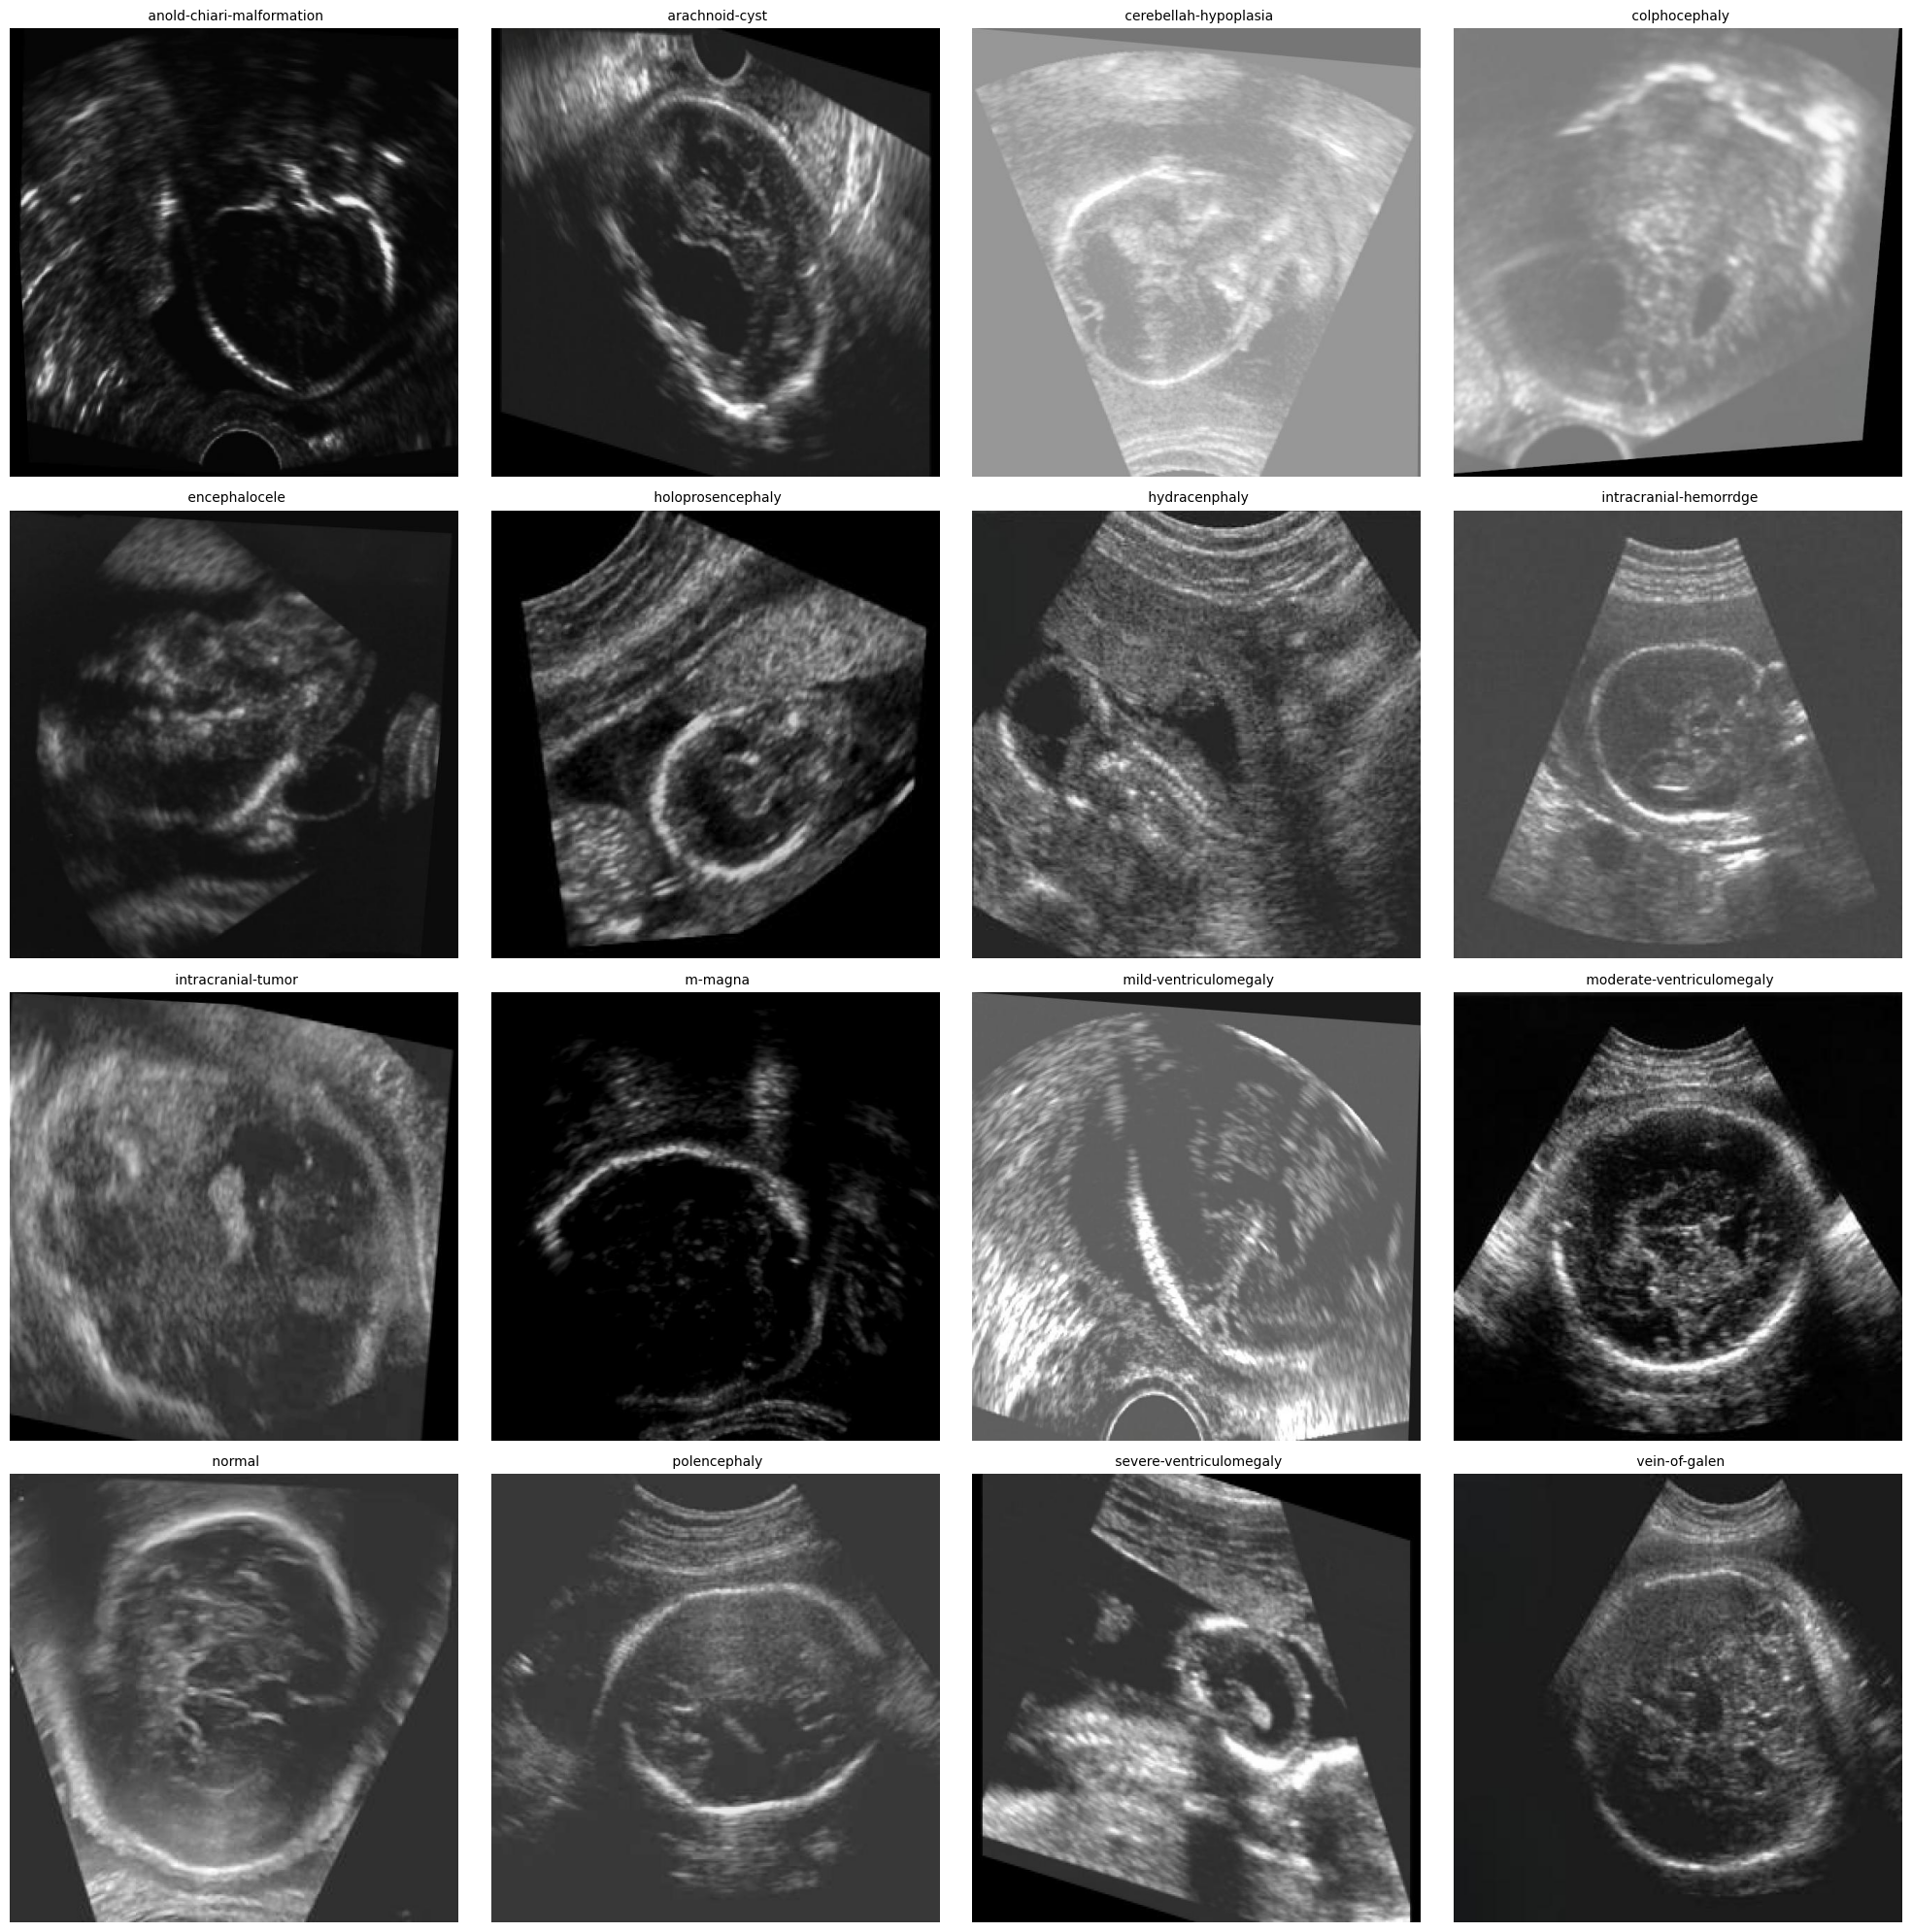

In [18]:
import math
classes = sorted(df["label"].unique())
num_classes = len(classes)
cols = 4
rows = math.ceil(num_classes / cols)
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows))
axes = axes.flatten()
for i, cls in enumerate(classes):
    sample = df[df["label"] == cls].sample(1).iloc[0]
    img_path = os.path.join(sample["split"], sample["filename"])
    img = Image.open(img_path)
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(cls, fontsize=10)
    axes[i].axis("off")
# Hide unused subplots
for j in range(num_classes, len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

In [19]:
width = []
height = []
for _, row in df.iterrows():
    img_path = os.path.join(
        row["split"],
        row["filename"]
    )
    img = Image.open(img_path)
    w, h = img.size
    width.append(w)
    height.append(h)

In [20]:
print("Average Width :", np.mean(width))
print("Average Height :", np.mean(height))
print("Minimum Width :", np.min(width))
print("Maximum Width :", np.max(width))
print("Minimum Height :", np.min(height))
print("Maximum Height :", np.max(height))

Average Width : 640.0
Average Height : 640.0
Minimum Width : 640
Maximum Width : 640
Minimum Height : 640
Maximum Height : 640


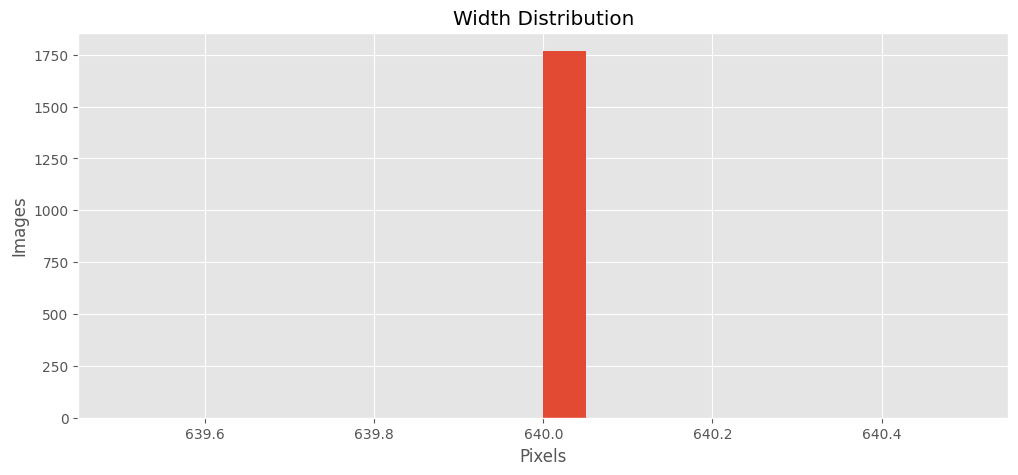

In [21]:
plt.figure(figsize=(12,5))
plt.hist(width,bins=20)
plt.title("Width Distribution")
plt.xlabel("Pixels")
plt.ylabel("Images")
plt.show()

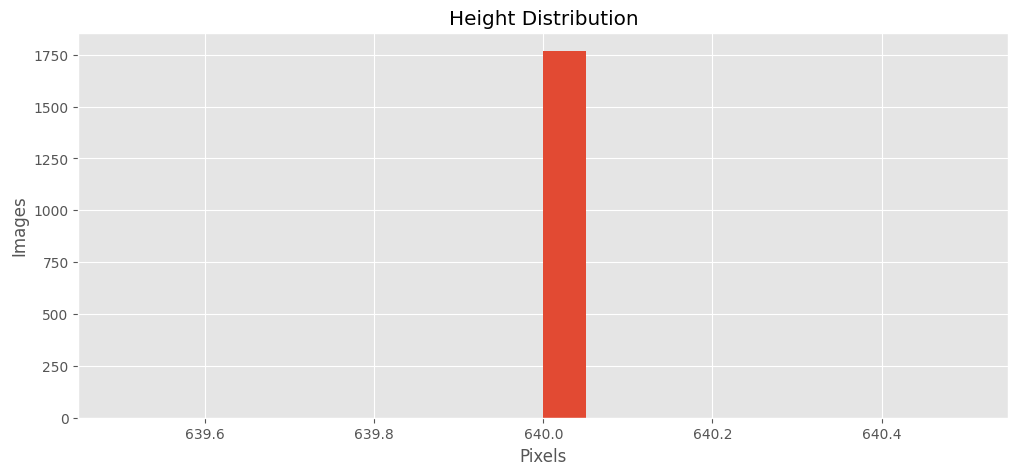

In [22]:
plt.figure(figsize=(12,5))
plt.hist(height,bins=20)
plt.title("Height Distribution")
plt.xlabel("Pixels")
plt.ylabel("Images")
plt.show()

In [23]:
corrupted = []
for _, row in df.iterrows():
    img_path = os.path.join(
        row["split"],
        row["filename"]
    )
    try:
        Image.open(img_path)
    except:
        corrupted.append(img_path)
print("Corrupted Images :", len(corrupted))

Corrupted Images : 0


In [24]:
class_counts = df["label"].value_counts().sort_values(ascending=False)
largest_class = class_counts.max()
smallest_class = class_counts.min()
imbalance_ratio = largest_class / smallest_class
print("Largest Class :", class_counts.idxmax())
print("Images :", largest_class)
print()
print("Smallest Class :", class_counts.idxmin())
print("Images :", smallest_class)
print()
print("Imbalance Ratio :", round(imbalance_ratio,2))

Largest Class :  moderate-ventriculomegaly
Images : 314

Smallest Class :  vein-of-galen
Images : 5

Imbalance Ratio : 62.8


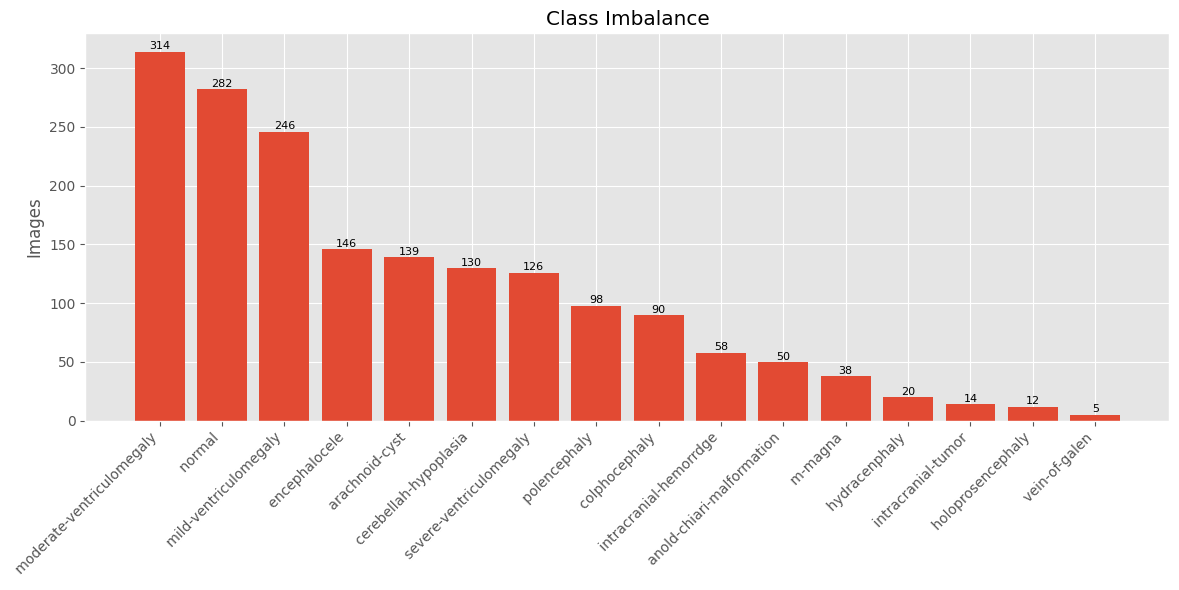

In [25]:
plt.figure(figsize=(12,6))
bars = plt.bar(class_counts.index,class_counts.values)
plt.xticks(rotation=45,ha="right")
plt.ylabel("Images")
plt.title("Class Imbalance")
for bar in bars:
    y = bar.get_height()
    plt.text(
        bar.get_x()+bar.get_width()/2,
        y+2,
        int(y),
        ha='center',
        fontsize=8
    )
plt.tight_layout()
plt.show()

In [26]:
summary = pd.DataFrame({
    "Metric":[
        "Total Images",
        "Total Classes",
        "Duplicate Images",
        "Corrupted Images",
        "Average Width",
        "Average Height",
        "Largest Class",
        "Smallest Class",
        "Imbalance Ratio"
    ],
    "Value":[
        len(df),
        len(class_counts),
        duplicates,
        len(corrupted),
        round(np.mean(width),2),
        round(np.mean(height),2),
        class_counts.idxmax(),
        class_counts.idxmin(),
        round(imbalance_ratio,2)
    ]
})
summary

,Metric,Value
0,Total Images,1768
1,Total Classes,16
2,Duplicate Images,0
3,Corrupted Images,0
4,Average Width,640.0
5,Average Height,640.0
6,Largest Class,moderate-ventriculomegaly
7,Smallest Class,vein-of-galen
8,Imbalance Ratio,62.8


In [27]:
summary.to_csv("Dataset_Summary.csv",index=False)

print("Summary Saved Successfully")

Summary Saved Successfully
